# Testing inference: multiple patterns in a long sequence

The trained readout from notebook 11 is loaded from the cache and probed **in retrieval
mode**: all 16 motifs are concatenated into one long input stream, each preceded by a long
spontaneous lull, and only its first `num_delay` ms is injected as a trigger. The network -
with no further plasticity - must then re-emit each motif from the correct onset onward.
This is a *chain-retrieval* stress test of the fixed weights (no retraining).

## Notebook summary

### Pipeline
1. Load `<datetag>_vanilla.pth` via `mnesis_chains.load()` (StochasticSpikingPattern).
2. Concatenate the 16 motifs (with long ITI pads) into a single `(N_neuron, T)` stream;
    build the per-motif trigger masks; run one single `forward_pass` on the stream.
3. Score every `window_size=20` ms position with `get_f1score(spikes_window, target_window)`,
    cached as `<datetag>_score.npy` under the standard `.lock` protocol.
4. Plot the F1 trajectory and an animated version (`retrieval.pdf` / `retrieval.mp4`).

### Main outputs
- cache `../cached_data/<datetag>_score.npy` (+ `.lock`);
- figures `retrieval.pdf/png/svg` and (when figpath is active) the `retrieval.mp4` animation.

### Notes
- Because the stream is processed by ONE forward pass, a motif can only be retrieved on the
   strength of its trigger + the network's own reverberations from the previous activity. 
   The network is not re-trained on the concatenated stream, 
   periodic troughs of the F1 curve around ITIs are expected.
- Remaining TODOs (training-vs-epochs, pruning, overlapping patterns) are future probes.


In [1]:
# load() rebuilds the HD_SNN architecture, restores <datetag>_vanilla.pth and
# attaches a default StochasticSpikingPattern (see mnesis_chains.load()).
from mnesis_boilerplate import torch, np, plt, data_cache, figpath, RECOMPUTE, phi, Params
from mnesis_boilerplate import printfig, get_f1score
from mnesis_chains import load
# RECOMPUTE = True
opt = Params()
model_filename = data_cache / f"{opt.datetag}_vanilla.pth"
hd = load(opt, model_filename)
print(f"Model weights loaded from {model_filename}")

datetag = '2026-09-07'
Using device: mps
Model weights loaded from ../cached_data/2026-09-07_vanilla.pth


In [2]:
print(f"Model weights loaded from {model_filename} - the pattern generator is the {hd.pattern_object.desc}")

Model weights loaded from ../cached_data/2026-09-07_vanilla.pth - the pattern generator is the Stochastic spike pattern generator


## Retrieval across a long concatenated sequence

Construction of the input stream (all tensors are finally reshaped to
`(N_neuron, N_pattern * (N_time + 2*N_iti_time))`):

- `target_full`: every motif padded by `N_iti_time = 4*N_pretime = 200` ms of silence and
   the 16 motifs concatenated head-to-tail - the *reference* to score against;
- `mask`: 1 on each motif's first `num_delay` bins, 0 elsewhere - keeps only the trigger;
- `input_spikes = target_full * mask`: the concatenated triggers (spontaneous activity is
   silenced here, unlike `get_input_spikes`, to isolate pure trigger-driven retrieval).

Scanning: `get_f1score` is evaluated in every `window_size=20` ms sliding window
(`onsets`), giving the per-position retrieval quality along the stream.

In [3]:
# One-shot scan: cached scores per 20-ms window along the concatenated stream.

window_size = 20

with torch.no_grad():
    N_iti_time = opt.N_pretime * 4
    target_full = torch.nn.functional.pad(hd.pattern_object(), (N_iti_time, N_iti_time))
    target_full = target_full.permute((1, 0, 2)).reshape((opt.N_neuron, opt.N_pattern*(opt.N_time+2*N_iti_time)))
    # target_full.shape

    evoked = torch.ones((opt.N_pattern, opt.N_neuron, opt.N_time), device=target_full.device)
    evoked = torch.nn.functional.pad(evoked, (N_iti_time, N_iti_time))
    evoked = evoked.permute((1, 0, 2)).reshape((opt.N_neuron, opt.N_pattern*(opt.N_time+2*N_iti_time)))

    mask = torch.ones((opt.N_pattern, opt.N_neuron, opt.N_time), device=target_full.device)
    mask[:, :, opt.num_delay:] *= 0
    mask = torch.nn.functional.pad(mask, (N_iti_time, N_iti_time))
    mask = mask.permute((1, 0, 2)).reshape((opt.N_neuron, opt.N_pattern*(opt.N_time+2*N_iti_time)))
    # mask.shape
    
    # noise = torch.bernoulli(opt.p_A * torch.ones((opt.N_neuron, opt.N_pattern *(opt.N_time+2*N_iti_time))))
    onsets = []
    for onset in np.arange(0, opt.N_pattern*(opt.N_time+2*N_iti_time)-window_size, window_size):
        onsets.append(onset)

    npy_filename = data_cache / f"{hd.opt.datetag}_score.npy"
    lock_filename = npy_filename.with_suffix('.lock')
    if RECOMPUTE:
        npy_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
        lock_filename.unlink(missing_ok=True) # FORCING RECOMPUTE
    try:
        scores_np = np.load(npy_filename)
        lock_filename.unlink(missing_ok=True) # in case the lock file was not unlinked
        print(f"Score weights loaded from {npy_filename}") # Add a log message
    except FileNotFoundError:
        if not lock_filename.exists():
            print(f"Score file not found: {npy_filename}, evaluating the score.")
            lock_filename.touch(exist_ok=True)
            ##################        
            input_spikes = (target_full * mask).unsqueeze(0)
            _, _, spikes = hd.forward_pass(input_spikes.to(opt.device))
            spikes = spikes.squeeze(0)
            print (spikes.shape)
            scores = []
            for onset in onsets:
                spikes_window = spikes[:, (onset):(onset+window_size)]
                target_window = target_full[:, (onset):(onset+window_size)]
                scores.append(get_f1score(spikes_window, target_window).cpu().numpy().item())
            ##################        
            scores_np = np.array(scores)
            np.save(npy_filename, scores_np)
            lock_filename.unlink(missing_ok=True)
        else:
            print(f"Score file is locked: {lock_filename}, passing.")

# Convert data to numpy arrays if needed
onsets_np = np.array(onsets)
evoked_np = evoked.cpu().numpy().mean(axis=0)[::window_size][:-1]
mask_np = mask.cpu().numpy().mean(axis=0)[::window_size][:-1]
scores_np.shape, evoked_np.shape

Score weights loaded from ../cached_data/2026-09-07_score.npy


((1119,), (1119,))

## F1 trajectory of the retrieval scan

Curves vs the onset time (ms): `evoked_np` (ideal 1 while a motif should be re-emitted -
the reference envelope), `mask_np` (1 only on each trigger's `num_delay`-ms window) and
`scores_np` (the measured per-window F1). Retrieval should light up after every trigger.

File ../figures/retrieval.pdf already exists. Skipping save.
File ../figures/retrieval.png already exists. Skipping save.
File ../figures/retrieval.svg already exists. Skipping save.


/var/folders/qt/n82pbkv93fjb7bpt0pj1992w0000gn/T/ipykernel_59386/220220000.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(loc='lower right')


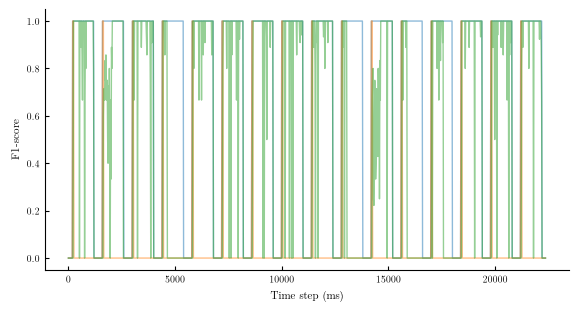

In [4]:
if not lock_filename.exists():
    fig, ax = plt.subplots()
    ax.plot(onsets_np, evoked_np, alpha=.5)
    ax.plot(onsets_np, mask_np, alpha=.5)
    ax.plot(onsets_np, scores_np, alpha=.5)
    ax.set_xlabel("Time step (ms)")
    ax.set_ylabel("F1-score")
    ax.legend(loc='lower right')

    printfig(fig, 'retrieval', fig_width=opt.fig_width, fig_height=opt.fig_height, figpath=figpath)

### Animated version

Same curves as a `window_size=100`-sample sliding viewport swept along the stream
(`ffmpeg`, 10 fps -> `retrieval.mp4`); colours: blue MNESIS (scores), red dashed the
ideal pattern, green dotted the trigger mask.

In [5]:
if not lock_filename.exists() and not figpath is None:

    filename = figpath / 'retrieval.mp4'
    if not filename.exists() or RECOMPUTE:    
        import matplotlib.animation as animation

        # Create the figure and axis
        fig, ax = plt.subplots(figsize=(opt.fig_width, opt.fig_width/phi))

        line2, = ax.plot([], [], 'r--', label='Pattern', linewidth=2, alpha=.5)
        line3, = ax.plot([], [], 'g:', label='Trigger', linewidth=2, alpha=.5)
        line1, = ax.plot([], [], 'b-', label='MNESIS', linewidth=2, alpha=.5)
        ax.set_xlabel("Time (ms)")
        ax.set_ylabel("F1-score")
        ax.legend(loc='lower right')

        window_size = 100
        total_steps = len(onsets_np)
        max_start = total_steps - window_size  # Maximum starting index
        y_min = min(scores_np.min(), evoked_np.min(), mask_np.min())
        y_max = max(scores_np.max(), evoked_np.max(), mask_np.max())
        if y_min == y_max:
            y_min, y_max = y_min - 0.1, y_max + 0.1
        y_range = y_max - y_min
        ax.set_ylim(y_min - 0.05 * y_range, y_max + 0.05 * y_range)

        def animate(frame):
            start_idx = frame
            end_idx = start_idx + window_size
            ax.set_xlim(start_idx, end_idx)
            if end_idx <= total_steps:
                x_data = np.arange(start_idx, end_idx)
                line1.set_data(x_data, scores_np[start_idx:end_idx])
                line2.set_data(x_data, evoked_np[start_idx:end_idx])
                line3.set_data(x_data, mask_np[start_idx:end_idx])
            
            return line1, line2, line3

        # Create animation - one frame for each possible window position
        anim = animation.FuncAnimation(
            fig, 
            animate, 
            frames=range(0, max_start + 1, 5),  # Step by 5 for smoother animation
            interval=50,  # 50ms between frames (~20 FPS)
            blit=False,
            repeat=True
        )

        # Save or display
        # Save as gif or mp4
        # anim.save(figpath / 'retrieval_animation.gif', writer='pillow', fps=20)
        anim.save(filename, writer='ffmpeg', fps=10)
        plt.close()